<a href="https://colab.research.google.com/github/EduardoKenzoHayashi/CN-Lobosco/blob/main/Continuacao_Interpolacao_Calculo_Numerico(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Continuação: interpolação numérica


Este notebook retoma a interpolação polinomial e avança para **diferenças divididas de Newton** e **avaliação do erro**. A ideia central é escolher uma representação adequada aos dados, e não apenas obter uma curva que passe por todos os pontos.

## Objetivos
- Construir o polinômio de Newton a partir de uma tabela de diferenças divididas.
- Atualizar o interpolador quando um novo dado é acrescentado.
- Medir erro em pontos conhecidos e discutir o que a validação permite concluir.


## 1. Preparação: dados de uma medição

Considere uma grandeza observada em instantes de tempo.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline, BarycentricInterpolator

x = np.array([0., 1., 2., 3., 4.])
y = np.array([1.0, 2.2, 1.8, 3.4, 3.0])

dados = pd.DataFrame({"x (tempo)": x, "y (medição)": y})
dados

,x (tempo),y (medição)
0,0.0,1.0
1,1.0,2.2
2,2.0,1.8
3,3.0,3.4
4,4.0,3.0


## 2. Diferenças divididas de Newton

Queremos construir um polinômio que passe exatamente pelos pontos conhecidos:

$$
(x_0,y_0),\ (x_1,y_1),\ \ldots,\ (x_n,y_n),
\qquad \text{com } y_i=f(x_i).
$$

A forma de Newton constrói o polinômio por etapas. Começamos pelo valor no primeiro nó e acrescentamos termos que ajustam a aproximação para incluir os nós seguintes:

$$
\begin{aligned}
P_n(x) ={}& f[x_0] \\
&+ f[x_0,x_1](x-x_0) \\
&+ f[x_0,x_1,x_2](x-x_0)(x-x_1) \\
&+ \cdots \\
&+ f[x_0,\ldots,x_n]
   (x-x_0)(x-x_1)\cdots(x-x_{n-1}).
\end{aligned}
$$

Em forma compacta:

$$
P_n(x)=
\sum_{k=0}^{n}
f[x_0,\ldots,x_k]
\prod_{j=0}^{k-1}(x-x_j).
$$
Para $k=0$, consideramos que o produto não tem fatores e vale $1$. Assim, o primeiro termo é $f[x_0]=y_0$,

Para k = 1:  o segundo contém o fator $(x-x_0),$

$$
\prod_{j=0}^{0}(x-x_j)=x-x_0
$$

Para k = 2:  o terceiro contém $(x-x_0)(x-x_1),$

$$
\prod_{j=0}^{1}(x-x_j)=(x-x_0)(x-x_1)
$$

Para k = 3: e cada termo seguinte acrescenta mais um fator.

$$
\prod_{j=0}^{2}(x-x_j)=(x-x_0)(x-x_1)(x-x_2)
$$
  



### O que é uma diferença dividida?

As diferenças divididas são quantidades calculadas a partir dos valores conhecidos nos nós. Elas permitem construir, passo a passo, o polinômio interpolador de Newton.

#### Diferença dividida de primeira ordem

Dados dois pontos, $(x_i,y_i)$ e $(x_{i+1},y_{i+1})$, a diferença dividida de primeira ordem é:

$$
f[x_i,x_{i+1}]
=
\frac{f(x_{i+1})-f(x_i)}{x_{i+1}-x_i}
=
\frac{y_{i+1}-y_i}{x_{i+1}-x_i}.
$$

Essa expressão é a inclinação da reta que passa pelos dois pontos. Ela mede a variação média de $f(x)$ entre os nós $x_i$ e $x_{i+1}$.

O denominador, $x_{i+1}-x_i$, representa a distância entre os nós. Por isso, a fórmula pode ser usada mesmo quando os pontos não estão igualmente espaçados.

#### Diferenças divididas de ordens superiores

Para calcular uma diferença dividida de ordem superior, usamos diferenças de ordem menor. A regra geral é:

$$
f[x_i,\ldots,x_{i+j}]
=
\frac{
f[x_{i+1},\ldots,x_{i+j}]
-
f[x_i,\ldots,x_{i+j-1}]
}{
x_{i+j}-x_i
},
\qquad j\geq 1.
$$

O numerador compara duas diferenças divididas de ordem anterior. O denominador é a distância entre o primeiro e o último nó do grupo considerado.

Todos os nós precisam ser distintos. Se dois nós forem iguais, o denominador pode ser zero e essa fórmula, na forma apresentada, não poderá ser aplicada.

### Exemplo com os dados deste notebook

Considere os cinco pontos:

$$
(0,1.0),\quad (1,2.2),\quad (2,1.8),\quad
(3,3.4),\quad (4,3.0).
$$

A diferença dividida entre os dois primeiros pontos é:

$$
\begin{aligned}
f[x_0,x_1]
&=
\frac{2.2-1.0}{1-0} \\
&=
1.2.
\end{aligned}
$$

Isso significa que, entre $x=0$ e $x=1$, o valor observado aumenta, em média, $1.2$ unidade para cada unidade de variação em $x$.

Entre os pontos seguintes, temos:

$$
\begin{aligned}
f[x_1,x_2]
&=
\frac{1.8-2.2}{2-1} \\
&=
-0.4.
\end{aligned}
$$

O resultado negativo indica que, entre $x=1$ e $x=2$, o valor observado diminui.

#### Calculando uma diferença de segunda ordem

A diferença dividida de segunda ordem para os três primeiros nós compara as duas inclinações calculadas acima:

$$
\begin{aligned}
f[x_0,x_1,x_2]
&=
\frac{f[x_1,x_2]-f[x_0,x_1]}{x_2-x_0} \\
&=
\frac{-0.4-1.2}{2-0} \\
&=
-0.8.
\end{aligned}
$$

Assim, a diferença de segunda ordem mede como as inclinações estão mudando entre os intervalos. Ela não é uma inclinação calculada diretamente entre dois pontos originais.

### Como organizar os cálculos em uma tabela

A tabela começa com os valores observados. Eles formam a coluna de **ordem zero**. Em seguida, cada coluna contém diferenças divididas de ordem crescente.

| Nó inicial | Ordem 0 | Ordem 1 | Ordem 2 | Ordem 3 | Ordem 4 |
|---|---:|---:|---:|---:|---:|
| $x_0=0$ | 1.0 | 1.2 | -0.8 | 0.8 | -0.5 |
| $x_1=1$ | 2.2 | -0.4 | 0.8 | -1.2 | |
| $x_2=2$ | 1.8 | 1.6 | -1.6 | | |
| $x_3=3$ | 3.4 | -0.4 | | | |
| $x_4=4$ | 3.0 | | | | |

Cada coluna tem um valor a menos que a coluna anterior, pois cada diferença é calculada a partir de dois valores da coluna precedente.

A próxima célula de código calcula essa tabela. Os coeficientes do polinômio de Newton são os valores da **primeira linha**:

$$
a_k=f[x_0,\ldots,x_k].
$$

### Como a tabela produz o polinômio

Para este exemplo, a primeira linha fornece os coeficientes:

$$
a_0=1.0,\qquad
a_1=1.2,\qquad
a_2=-0.8,\qquad
a_3=0.8,\qquad
a_4=-0.5.
$$

Substituindo esses coeficientes na forma de Newton, obtemos:

$$
\begin{aligned}
P_4(x) ={}&
1.0
+1.2(x-0) \\
&-0.8(x-0)(x-1) \\
&+0.8(x-0)(x-1)(x-2) \\
&-0.5(x-0)(x-1)(x-2)(x-3).
\end{aligned}
$$

Não é necessário expandir o polinômio em potências de $x$. A forma de Newton mantém explícitos os fatores associados aos nós e facilita a inclusão de novos termos.

#### Por que o polinômio passa pelos pontos?

Quando substituímos $x=x_0$, todos os termos depois do primeiro contêm o fator $(x-x_0)$ e se anulam. Portanto:

$$
P_4(x_0)=f[x_0]=y_0.
$$

Quando substituímos $x=x_1$, os termos a partir do terceiro contêm o fator $(x-x_1)$ e se anulam. Os dois primeiros termos reproduzem o valor do segundo ponto:

$$
P_4(x_1)
=
f[x_0]+f[x_0,x_1](x_1-x_0)
=
y_1.
$$

O mesmo princípio se aplica aos demais nós: os fatores dos termos posteriores fazem com que eles se anulem nos nós já considerados. Assim, o polinômio reproduz todos os valores da tabela.

### Interpretando a forma de Newton

- **Ordem zero:** contém os valores observados.
- **Primeira ordem:** representa as inclinações entre pares de pontos.
- **Ordens superiores:** descrevem mudanças sucessivas nessas inclinações e contribuem para definir a forma do polinômio.
- **Coeficientes:** são lidos na primeira linha da tabela de diferenças divididas.

Uma vantagem prática é que podemos acrescentar um novo ponto ao final da sequência sem recalcular os coeficientes anteriores. Basta calcular o novo coeficiente e adicionar um novo termo ao polinômio.

A ordem dos nós altera a tabela e a maneira como o polinômio é escrito na forma de Newton. Porém, para os mesmos pontos com nós distintos, o polinômio interpolador final é único.

> **Atenção:** o polinômio reproduz exatamente os valores nos nós, mas isso não garante que represente bem o comportamento entre eles. Com muitos nós, dados ruidosos ou extrapolação fora do intervalo medido, a aproximação pode apresentar grandes erros. Por isso, é importante comparar o resultado com outros métodos, como splines, e analisar o erro.

In [2]:
def tabela_diferencas_divididas(x, y):
    """Retorna tabela triangular de diferenças divididas."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if len(x) != len(y):
        raise ValueError("x e y devem ter o mesmo tamanho")
    if len(np.unique(x)) != len(x):
        raise ValueError("Os nós x devem ser distintos")
    n = len(x)
    tabela = np.zeros((n, n), dtype=float)
    tabela[:, 0] = y
    for j in range(1, n):
        for i in range(n-j):
            tabela[i, j] = (tabela[i+1, j-1] - tabela[i, j-1]) / (x[i+j] - x[i])
    return tabela

tabela = tabela_diferencas_divididas(x, y)
pd.DataFrame(tabela, columns=[f"ordem {j}" for j in range(len(x))])

,ordem 0,ordem 1,ordem 2,ordem 3,ordem 4
0,1.0,1.2,-0.8,0.600000,-0.316667
1,2.2,-0.4,1.0,-0.666667,0.000000
2,1.8,1.6,-1.0,0.000000,0.000000
3,3.4,-0.4,0.0,0.000000,0.000000
4,3.0,0.0,0.0,0.000000,0.000000


Leia os coeficientes na primeira linha: $a_j=f[x_0,\ldots,x_j]$. O coeficiente de ordem $j$ multiplica um produto com $j$ fatores. Observe como os valores diminuem ou aumentam de ordem.

In [3]:
coef = tabela[0, :]
print("Coeficientes de Newton:")
for j, a in enumerate(coef):
    print(f"a_{j} = {a:.8g}")

Coeficientes de Newton:
a_0 = 1
a_1 = 1.2
a_2 = -0.8
a_3 = 0.6
a_4 = -0.31666667


### Avaliação eficiente

A expressão pode ser avaliada sem expandir o polinômio em potências. Isso evita uma expansão algébrica desnecessária e facilita incluir novos nós.

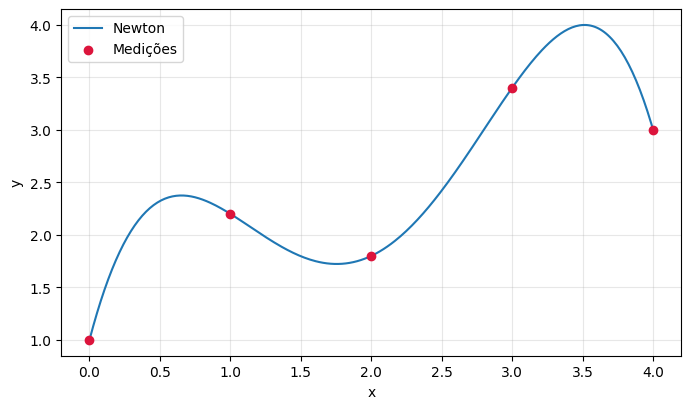

Valores nos nós: [1.  2.2 1.8 3.4 3. ]


In [4]:
def newton_avaliar(x_nos, coef, z):
    """Avalia o polinômio de Newton em escalar ou array z."""
    x_nos = np.asarray(x_nos, dtype=float)
    z = np.asarray(z, dtype=float)
    resultado = np.zeros_like(z, dtype=float) + coef[-1]
    for k in range(len(coef)-2, -1, -1):
        resultado = coef[k] + (z - x_nos[k]) * resultado
    return resultado

z = np.linspace(x.min(), x.max(), 300)
p_newton = newton_avaliar(x, coef, z)
plt.figure(figsize=(8, 4.5))
plt.plot(z, p_newton, label="Newton")
plt.scatter(x, y, color="crimson", zorder=3, label="Medições")
plt.xlabel("x"); plt.ylabel("y"); plt.grid(True, alpha=.3); plt.legend(); plt.show()

print("Valores nos nós:", newton_avaliar(x, coef, x))

## 3. Atualização com um novo dado

Uma vantagem da forma de Newton é que, quando adicionamos um novo nó ao final da lista, os coeficientes anteriores permanecem válidos; calculamos apenas os termos adicionais. Vamos comparar o ajuste com quatro e cinco pontos.

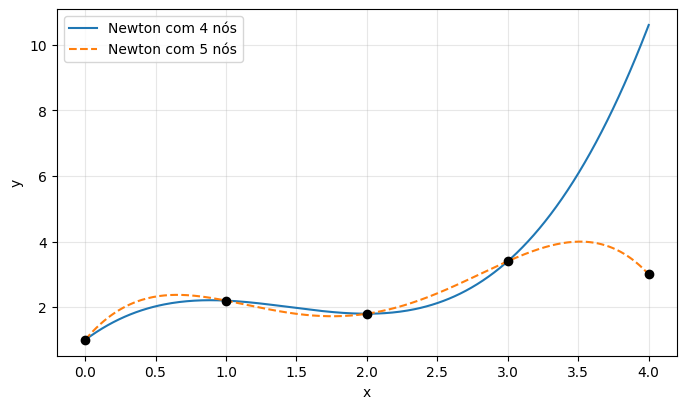

In [5]:
n4 = 4
x4, y4 = x[:n4], y[:n4]
coef4 = tabela_diferencas_divididas(x4, y4)[0, :]
coef5 = tabela_diferencas_divididas(x, y)[0, :]
z = np.linspace(0, 4, 300)
plt.figure(figsize=(8, 4.5))
plt.plot(z, newton_avaliar(x4, coef4, z), label="Newton com 4 nós")
plt.plot(z, newton_avaliar(x, coef5, z), "--", label="Newton com 5 nós")
plt.scatter(x, y, color="black", zorder=3)
plt.xlabel("x"); plt.ylabel("y"); plt.grid(True, alpha=.3); plt.legend(); plt.show()

## 4. Interpolação global e spline cúbica

Há diferentes maneiras de construir uma curva que passe por um conjunto de pontos conhecidos. Nesta seção, vamos comparar duas delas: a interpolação polinomial global e a interpolação por spline cúbica.

### 4.1 Interpolação polinomial global

Na interpolação global, construímos um único polinômio que usa todos os nós. Para \(n+1\) pontos, o polinômio tem grau no máximo \(n\):

$$
P_n(x_i)=y_i,\qquad i=0,1,\ldots,n.
$$

Esse polinômio é calculado em todo o intervalo dos dados. Por isso, uma mudança na posição ou no valor de um nó pode afetar a curva em uma região ampla do domínio.

Quando há poucos pontos, o polinômio global pode ser simples e funcionar bem. Porém, ao aumentar o número de nós, seu grau também pode aumentar. Em alguns casos, isso provoca oscilações entre os pontos, principalmente perto das extremidades do intervalo. Esse comportamento é conhecido como fenômeno de Runge.

### 4.2 Interpolação por spline cúbica

A spline cúbica usa um polinômio diferente em cada intervalo entre dois nós consecutivos. No intervalo \([x_i,x_{i+1}]\), a spline tem a forma

$$
S_i(x)=a_i+b_i(x-x_i)+c_i(x-x_i)^2+d_i(x-x_i)^3.
$$

Os coeficientes são escolhidos para que cada trecho passe pelos dados nas extremidades do intervalo. Além disso, nos nós internos, os trechos vizinhos são conectados com suavidade. Em uma spline cúbica usual, impomos continuidade:

- da função \(S(x)\);
- da primeira derivada \(S'(x)\);
- da segunda derivada \(S''(x)\).

Assim, a curva não apresenta saltos nem mudanças abruptas de inclinação ou de curvatura nos nós internos.

Para determinar uma spline cúbica, também precisamos especificar condições nas extremidades do intervalo. Uma escolha comum é a **spline natural**, que impõe segunda derivada nula nos dois extremos:

$$
S''(x_0)=0,\qquad S''(x_n)=0.
$$

### 4.3 Diferença entre as abordagens

As duas abordagens passam pelos pontos fornecidos, mas podem apresentar comportamentos diferentes entre eles:

- O polinômio global usa todos os nós em uma única expressão. Alterar um dado pode afetar a curva em todo o domínio.
- A spline cúbica usa polinômios locais, um em cada intervalo. Uma alteração em um nó tende a afetar principalmente os trechos próximos.
- O polinômio global pode oscilar quando seu grau é alto.
- A spline cúbica costuma produzir uma curva suave e flexível, mas o resultado depende das condições escolhidas nas extremidades.

A spline não é necessariamente mais precisa em qualquer situação. A escolha do método deve considerar o comportamento esperado da função e a finalidade da interpolação.

### 4.4 O que observar na comparação

Ao comparar as curvas, observe:

1. se ambas passam pelos pontos conhecidos;
2. como cada curva se comporta entre os nós;
3. se há oscilações ou mudanças acentuadas de curvatura;
4. como a curva se comporta perto das extremidades;
5. se o formato entre os dados é compatível com o fenômeno estudado.

Passar exatamente pelos dados não garante que a curva represente corretamente o comportamento entre eles. Quando a função original é conhecida, podemos comparar os erros. Quando ela é desconhecida, a escolha deve considerar conhecimento do problema e dados de validação.

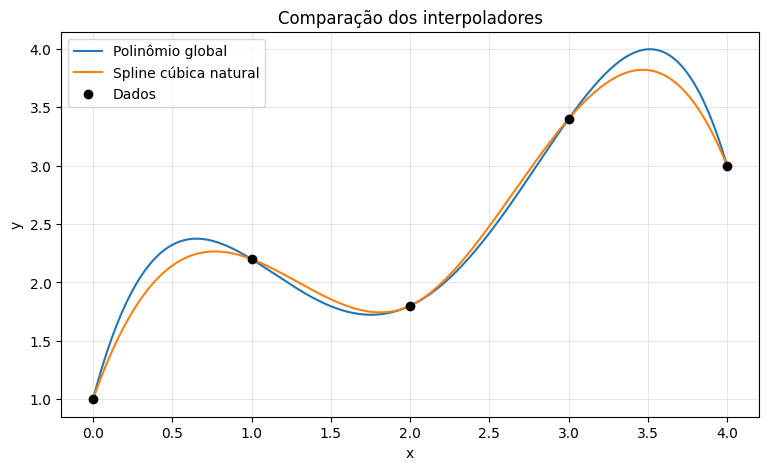

In [6]:
spline = CubicSpline(x, y)  # condição natural nas extremidades
interp_global = BarycentricInterpolator(x, y)
z = np.linspace(x.min(), x.max(), 400)
plt.figure(figsize=(9, 5))
plt.plot(z, interp_global(z), label="Polinômio global")
plt.plot(z, spline(z), label="Spline cúbica natural")
plt.scatter(x, y, color="black", zorder=3, label="Dados")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Comparação dos interpoladores")
plt.grid(True, alpha=.3); plt.legend(); plt.show()

Estimativa do erro de interpolação e fórmula de Newton
Objetivos

Construir o polinômio de Newton; interpretar a fórmula do erro; comparar estimativas com o erro real quando a função é conhecida.

## 1. Problema de interpolação

Dados nós distintos $(x_0,x_1,\ldots,x_n)$, procuramos um polinômio (P_n) tal que

$$P_n(x_i)=f(x_i),\quad i=0,1,\ldots,n.$$

O erro em $(x)$ é $(E_n(x)=f(x)-P_n(x))$. Nos nós, o erro é zero; nos demais pontos, em geral, não.

## 2. Fórmula de Newton

$$P_n(x)=\sum_{k=0}^{n} f[x_0,\ldots,x_k]\prod_{j=0}^{k-1}(x-x_j).$$

Os coeficientes são diferenças divididas. A primeira ordem é

$$f[x_i,x_{i+1}]=\frac{f(x_{i+1})-f(x_i)}{x_{i+1}-x_i},$$

e as ordens superiores são calculadas por

$$f[x_i,\ldots,x_{i+j}]=\frac{f[x_{i+1},\ldots,x_{i+j}]-f[x_i,\ldots,x_{i+j-1}]}{x_{i+j}-x_i}.$$

Cada termo novo acrescenta uma correção sem alterar os valores já interpolados nos nós anteriores.

## 3. Exemplo: interpolação de $f(x) = e^x$

Vamos construir um polinômio de grau no máximo 2 que aproxime a função exponencial nos nós

$$
x_0 = 0, \qquad x_1 = 0.5, \qquad x_2 = 1.
$$

Calculamos primeiro os valores da função nesses nós:

$$
f(x_0) = e^0 = 1,
$$

$$
f(x_1) = e^{0.5} \approx 1.648721,
$$

$$
f(x_2) = e^1 \approx 2.718282.
$$

O polinômio interpolador de Newton para três nós é

$$
P_2(x) =
f[x_0]
+ f[x_0,x_1](x-x_0)
+ f[x_0,x_1,x_2](x-x_0)(x-x_1).
$$

Cada termo acrescenta uma correção:

- $f[x_0]$ fornece o valor do polinômio no primeiro nó.
- $f[x_0,x_1](x-x_0)$ acrescenta o termo linear e ajusta o polinômio ao segundo nó.
- $f[x_0,x_1,x_2](x-x_0)(x-x_1)$ acrescenta o termo quadrático e ajusta o polinômio ao terceiro nó, sem alterar os valores já ajustados nos dois primeiros.

As diferenças divididas de primeira ordem são

$$
f[x_0,x_1]
=
\frac{f(x_1)-f(x_0)}{x_1-x_0},
\qquad
f[x_1,x_2]
=
\frac{f(x_2)-f(x_1)}{x_2-x_1}.
$$

A diferença dividida de segunda ordem é

$$
f[x_0,x_1,x_2]
=
\frac{f[x_1,x_2]-f[x_0,x_1]}{x_2-x_0}.
$$

Na tabela de diferenças divididas, os coeficientes do polinômio são lidos na primeira linha:

$$
a_0=f[x_0], \qquad
a_1=f[x_0,x_1], \qquad
a_2=f[x_0,x_1,x_2].
$$

Assim, podemos escrever

$$
P_2(x)=a_0+a_1(x-x_0)+a_2(x-x_0)(x-x_1).
$$

O polinômio reproduz exatamente os valores da função nos três nós. Entre esses pontos, ele fornece uma aproximação para $e^x$.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

def dd_table(nodes, values):
    m = len(nodes)
    table = np.zeros((m,m))
    table[:,0] = values
    for j in range(1,m):
        for i in range(m-j):
            table[i,j] = (table[i+1,j-1]-table[i,j-1])/(nodes[i+j]-nodes[i])
    return table

def newton_eval(x, nodes, coeff):
    x = np.asarray(x, dtype=float)
    value = np.zeros_like(x) + coeff[-1]
    for j in range(len(coeff)-2,-1,-1):
        value = coeff[j] + (x-nodes[j])*value
    return value

f = np.exp
nodes = np.array([0.0,0.5,1.0])
D = dd_table(nodes,f(nodes))
coeff = D[0,:]
print(pd.DataFrame(D,columns=[f"ordem {j}" for j in range(len(nodes))]).round(6))
print("Coeficientes de Newton:",coeff)

    ordem 0   ordem 1   ordem 2
0  1.000000  1.297443  0.841679
1  1.648721  2.139121  0.000000
2  2.718282  0.000000  0.000000
Coeficientes de Newton: [1.         1.29744254 0.84167857]


### Cálculo passo a passo dos coeficientes de Newton

Para os nós $(x_0=0)$, $(x_1=0.5)$ e $(x_2=1)$, usamos os valores:

$$
f(x_0)=1,\qquad
f(x_1)\approx 1.648721,\qquad
f(x_2)\approx 2.718282.
$$

A primeira diferença dividida entre \(x_0\) e \(x_1\) é

$$
f[x_0,x_1]
=
\frac{f(x_1)-f(x_0)}{x_1-x_0}
=
\frac{1.648721-1}{0.5-0}
\approx 1.297442.
$$

Entre \(x_1\) e \(x_2\), temos

$$
f[x_1,x_2]
=
\frac{f(x_2)-f(x_1)}{x_2-x_1}
=
\frac{2.718282-1.648721}{1-0.5}
\approx 2.139122.
$$

Agora calculamos a diferença dividida de segunda ordem:

$$
f[x_0,x_1,x_2]
=
\frac{f[x_1,x_2]-f[x_0,x_1]}{x_2-x_0}
\approx
\frac{2.139122-1.297442}{1-0}
\approx 0.841680.
$$

Portanto, o polinômio interpolador de Newton é

$$
P_2(x)
=
1
+
1.297442(x-0)
+
0.841680(x-0)(x-0.5).
$$

Esse polinômio passa exatamente pelos três pontos usados na interpolação. Entre os nós, seus valores aproximam \(e^x\).

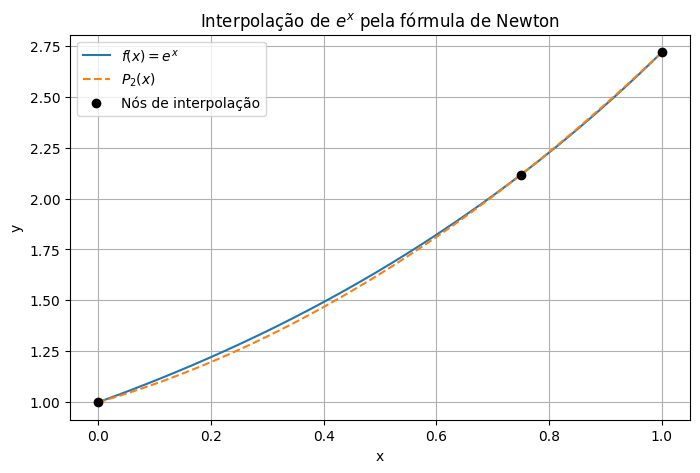

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Nós e valores da função
x_nodes = np.array([0.0, 0.75, 1.0])
y_nodes = np.exp(x_nodes)

# Coeficientes calculados pelas diferenças divididas
a0 = y_nodes[0]
a1 = (y_nodes[1] - y_nodes[0]) / (x_nodes[1] - x_nodes[0])
a2 = ((y_nodes[2] - y_nodes[1]) / (x_nodes[2] - x_nodes[1]) - a1) / (x_nodes[2] - x_nodes[0])

def P2(x):
    return a0 + a1 * (x - x_nodes[0]) + a2 * (x - x_nodes[0]) * (x - x_nodes[1])

# Comparação entre a função e o interpolador
x_plot = np.linspace(0, 1, 300)

plt.figure(figsize=(8, 5))
plt.plot(x_plot, np.exp(x_plot), label=r"$f(x)=e^x$")
plt.plot(x_plot, P2(x_plot), "--", label=r"$P_2(x)$")
plt.scatter(x_nodes, y_nodes, color="black", zorder=3, label="Nós de interpolação")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Interpolação de $e^x$ pela fórmula de Newton")
plt.grid(True)
plt.legend()
plt.show()

### Atividade: comparar o interpolador de Newton com a função $(e^x)$

Vamos usar os nós

$$
x_0=0,\qquad x_1=0.5,\qquad x_2=1
$$

para construir o polinômio interpolador quadrático $(P_2(x))$.

Depois, vamos avaliar o polinômio em dois pontos que não são nós: $(x=0.25)$ e $(x=0.75)$. Em cada ponto, compararemos o valor aproximado pelo polinômio com o valor exato da função $(e^x)$.

#### Passo 1 — Calcular os valores da função nos nós

Calculamos $(f(x_i)=e^{x_i})$ para cada nó:

$$
f(0)=e^0=1,
$$

$$
f(0.5)=e^{0.5}\approx 1.648721,
$$

$$
f(1)=e^1\approx 2.718282.
$$

Esses são os valores que o polinômio deve reproduzir exatamente nos nós.

#### Passo 2 — Calcular as diferenças divididas

A primeira diferença dividida entre $(x_0)$ e $(x_1)$ é

$$
f[x_0,x_1]
=
\frac{f(x_1)-f(x_0)}{x_1-x_0}.
$$

Entre $(x_1)$ e $(x_2)$, calculamos

$$
f[x_1,x_2]
=
\frac{f(x_2)-f(x_1)}{x_2-x_1}.
$$

A diferença dividida de segunda ordem é

$$
f[x_0,x_1,x_2]
=
\frac{f[x_1,x_2]-f[x_0,x_1]}{x_2-x_0}.
$$

#### Passo 3 — Escrever o polinômio de Newton

Com os coeficientes calculados, formamos

$$
P_2(x)
=
f[x_0]
+
f[x_0,x_1](x-x_0)
+
f[x_0,x_1,x_2](x-x_0)(x-x_1).
$$

Como $(x_0=0)$ e $(x_1=0.5)$, também podemos escrever

$$
P_2(x)
=
f(0)
+
f[x_0,x_1]x
+
f[x_0,x_1,x_2]x(x-0.5).
$$

#### Passo 4 — Avaliar em pontos que não são nós

Vamos calcular $(P_2(0.25))$ e $(P_2(0.75))$. Esses valores são aproximações para $(e^{0.25})$ e $(e^{0.75})$.

#### Passo 5 — Calcular os erros

Como conhecemos a função exata, calculamos o erro em cada ponto pela diferença entre o valor exato e o aproximado:

$$
E_2(x)=e^x-P_2(x).
$$

Também calculamos o erro absoluto:

$$
|E_2(x)|=|e^x-P_2(x)|.
$$

O erro absoluto facilita a comparação, pois indica o tamanho do erro sem considerar se a aproximação ficou acima ou abaixo do valor exato.

#### Passo 6 — Comparar os resultados

Observe os erros absolutos nos dois pontos. Verifique em qual deles a aproximação foi mais precisa. O resultado depende da posição do ponto em relação aos nós e do comportamento da função entre eles.

In [9]:
import numpy as np
import pandas as pd

# Função que será interpolada
def f(x):
    return np.exp(x)

# Nós de interpolação
x_nodes = np.array([0.0, 0.5, 1.0])
y_nodes = f(x_nodes)

# Diferenças divididas
f_x0_x1 = (y_nodes[1] - y_nodes[0]) / (x_nodes[1] - x_nodes[0])
f_x1_x2 = (y_nodes[2] - y_nodes[1]) / (x_nodes[2] - x_nodes[1])

f_x0_x1_x2 = (
    f_x1_x2 - f_x0_x1
) / (x_nodes[2] - x_nodes[0])

# Coeficientes da forma de Newton
a0 = y_nodes[0]
a1 = f_x0_x1
a2 = f_x0_x1_x2

print("Valores da função nos nós:")
for x, y in zip(x_nodes, y_nodes):
    print(f"f({x:.2f}) = {y:.8f}")

print("\nDiferenças divididas:")
print(f"f[x0, x1]     = {a1:.8f}")
print(f"f[x1, x2]     = {f_x1_x2:.8f}")
print(f"f[x0, x1, x2] = {a2:.8f}")

print("\nPolinômio de Newton:")
print(
    f"P2(x) = {a0:.8f} "
    f"+ ({a1:.8f})(x - {x_nodes[0]:.1f}) "
    f"+ ({a2:.8f})(x - {x_nodes[0]:.1f})(x - {x_nodes[1]:.1f})"
)

# Avaliação do polinômio na forma de Newton
def P2(x):
    return (
        a0
        + a1 * (x - x_nodes[0])
        + a2 * (x - x_nodes[0]) * (x - x_nodes[1])
    )

# Pontos de teste: não são nós de interpolação
x_test = np.array([0.2, 0.7])

# Valores exatos e aproximados
y_exact = f(x_test)
y_approx = P2(x_test)

# Erros com sinal e erros absolutos
error = y_exact - y_approx
absolute_error = np.abs(error)

# Tabela de comparação
comparison = pd.DataFrame({
    "x": x_test,
    "Valor exato e^x": y_exact,
    "Aproximação P2(x)": y_approx,
    "Erro e^x - P2(x)": error,
    "Erro absoluto": absolute_error
})

print("\nComparação nos pontos de teste:")
display(comparison.round(8))

# Identificação do ponto com maior erro absoluto
index_max = np.argmax(absolute_error)
print(
    f"\nO maior erro absoluto ocorreu em x = {x_test[index_max]:.2f}, "
    f"com valor {absolute_error[index_max]:.8e}."
)

Valores da função nos nós:
f(0.00) = 1.00000000
f(0.50) = 1.64872127
f(1.00) = 2.71828183

Diferenças divididas:
f[x0, x1]     = 1.29744254
f[x1, x2]     = 2.13912112
f[x0, x1, x2] = 0.84167857

Polinômio de Newton:
P2(x) = 1.00000000 + (1.29744254)(x - 0.0) + (0.84167857)(x - 0.0)(x - 0.5)

Comparação nos pontos de teste:


,x,Valor exato e^x,Aproximação P2(x),Erro e^x - P2(x),Erro absoluto
0,0.2,1.221403,1.208988,0.012415,0.012415
1,0.7,2.013753,2.026045,-0.012292,0.012292



O maior erro absoluto ocorreu em x = 0.20, com valor 1.24149643e-02.
